In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
db_path = '/content/drive/My Drive/Data/database.sqlite'

In [ ]:
conn = sqlite3.connect(db_path)

In [ ]:
from re import A
# Kapitel 1: Setup

#Hilfsfunktion:

def get_season(date_obj):
    year = date_obj.year
    month = date_obj.month

    if month >= 7:
        return str(year) + "/" + str(year+1)

    else:
        return str(year-1) + "/" + str(year)

def get_last_possession(xml_string):

    if xml_string is None or not isinstance(xml_string, str):
        return None, None
    try:
        root = ET.fromstring(xml_string)
        values = []
        for value in root.findall('value'):
            try:
                elapsed = int(value.find('elapsed').text)
                stats = value.find('stats')
                if stats is not None:
                    home = int(stats.find('homepos').text)
                    away = int(stats.find('awaypos').text)
                    values.append((elapsed, home, away))
                else:
                    home = int(value.find('homepos').text)
                    away = int(value.find('awaypos').text)
                    values.append((elapsed, home, away))
            except (AttributeError, ValueError):
                continue

        if not values:
            return None, None

        values.sort(key=lambda x: x[0])
        final_stat = values[-1]
        return final_stat[1], final_stat[2]
    except ET.ParseError:
        return None, None

def get_match_result(row):

  home = row['home_team_goal']
  away = row['away_team_goal']

  if pd.isna(home) or pd.isna(away):
    return None

  if home == away:
    return 'Draw'

  elif home > away:
    return 'HomeWin'

  else:
    return 'AwayWin'

def get_team_result(row):

    my_goals = row['team_goal']
    opp_goals = row['opponent_goal']

    if pd.isna(my_goals) or pd.isna(opp_goals):
        return None

    if my_goals > opp_goals:
        return 'Win'
    elif my_goals < opp_goals:
        return 'Loss'
    else:
        return 'Draw'


def determine_position(row):
  def_score = (row["marking"] + row["standing_tackle"] + row["sliding_tackle"] + row["interceptions"]) / 4
  att_score = (row["finishing"] + row["volleys"] + row["positioning"] + row["long_shots"]) / 4
  mid_score = (row["short_passing"] + row["long_passing"] + row["vision"] + row["ball_control"]) / 4

  if att_score > def_score and att_score > mid_score:
    return "Attacker"
  elif def_score > att_score and def_score > mid_score:
    return "Defender"
  else:
    return "Midfielder"

In [ ]:
# Kapitel 2: Core Datawarehouse


#2.1/2.2 Core table: Goals and assists

goal_query = "SELECT match_api_id, date, goal FROM Match WHERE goal IS NOT NULL"

df_matches_raw = pd.read_sql_query(goal_query, conn)

goals_data = []
assists_data = []

for index, row in df_matches_raw.iterrows():
  xml_string = row['goal']
  events = xml_string.split('<value>')

  for event in events:
    if '<player1>' in event:
      teil_nach_start = event.split('<player1>')[1]
      player_id = teil_nach_start.split('</player1>')[0]

      goals_data.append({'match_api_id': row['match_api_id'],
                         'date': row['date'],
                         'scorer_id': player_id})

    if '<player2>' in event:
      teil_nach_start = event.split('<player2>')[1]
      player_id = teil_nach_start.split('</player2>')[0]

      assists_data.append({'match_api_id': row['match_api_id'],
                         'date': row['date'],
                         'assist_id': player_id})



df_core_goals = pd.DataFrame(goals_data)
df_core_goals['date'] = pd.to_datetime(df_core_goals['date'])
df_core_goals['scorer_id'] = pd.to_numeric(df_core_goals['scorer_id'])
df_core_goals['season'] = df_core_goals['date'].apply(get_season)

df_core_assists = pd.DataFrame(assists_data)
df_core_assists['date'] = pd.to_datetime(df_core_assists['date'])
df_core_assists['assist_id'] = pd.to_numeric(df_core_assists['assist_id'])
df_core_assists['season'] = df_core_assists['date'].apply(get_season)


In [ ]:
#2.3 Core Tabelle: Attributes (Jede Änderung einzeln)

goal_attributes_query = """
SELECT
      player_api_id,
       date,
       overall_rating,
       finishing,
       heading_accuracy,
       volleys,
       curve,
       ball_control,
       acceleration,
       sprint_speed,
       agility,
       reactions,
       shot_power,
       stamina,
       strength,
       long_shots,
       positioning,
       vision,
       long_passing,
       crossing,
       short_passing,
       marking,
       standing_tackle,
       sliding_tackle,
       interceptions
      From Player_Attributes
    """
df_attributes_goal = pd.read_sql_query(goal_attributes_query, conn)
df_attributes_goal['date'] =  pd.to_datetime(df_attributes_goal['date'])
df_attributes_goal['season'] = df_attributes_goal['date'].apply(get_season)

In [ ]:
#2.4 Core Tabelle: Matches (jedes Match einzeln)

match_query = "SELECT match_api_id, date, home_team_goal, away_team_goal, possession, home_team_api_id, away_team_api_id, league_id FROM Match"
df_core_matches = pd.read_sql_query(match_query, conn)
df_core_matches['date'] = pd.to_datetime(df_core_matches['date'])
df_core_matches['season'] = df_core_matches['date'].apply(get_season)

df_core_matches[['home_possession', 'away_possession']] = df_core_matches['possession'].apply(
    lambda x: pd.Series(get_last_possession(x))
)

df_core_matches = df_core_matches.drop(columns=['possession'])

df_home = df_core_matches.copy()
df_home = df_home.rename(columns={
    'home_team_api_id': 'team_api_id',
    'home_team_goal': 'team_goal',
    'away_team_goal': 'opponent_goal',
    'home_possession': 'possession'
})
df_home['venue'] = 'Home'

df_away = df_core_matches.copy()
df_away = df_away.rename(columns={
    'away_team_api_id': 'team_api_id',
    'away_team_goal': 'team_goal',
    'home_team_goal': 'opponent_goal',
    'away_possession': 'possession'
})
df_away['venue'] = 'Away'

keep_cols = ['match_api_id', 'date', 'season', 'league_id', 'team_api_id',
             'team_goal', 'opponent_goal', 'possession', 'venue']

df_home = df_home[keep_cols]
df_away = df_away[keep_cols]

df_core_matches = pd.concat([df_home, df_away], ignore_index=True)

df_core_matches['result'] = df_core_matches.apply(get_team_result, axis=1)

df_core_matches['goal_diff'] = df_core_matches['team_goal'] - df_core_matches['opponent_goal']

df_core_matches['total_goals'] = df_core_matches['team_goal'] + df_core_matches['opponent_goal']

df_core_matches['time_key'] = df_core_matches['date'].dt.strftime('%Y%m%d').astype(int)

df_core_matches = df_core_matches.sort_values(by=['match_api_id', 'venue'])






In [ ]:
#starsheme by saison(Question 1)
sql_query_dim_player_1 = "SELECT player_api_id, player_name, birthday, height, weight FROM Player"

dim_player_1 = pd.read_sql_query(sql_query_dim_player_1, conn)
dim_season_1 = pd.DataFrame(df_core_goals['season'].unique(), columns=['season_id'])

fact_goals_agg = df_core_goals.groupby(['scorer_id', 'season']).size().reset_index(name='goals_count')
fact_assists_agg = df_core_assists.groupby(['assist_id', 'season']).size().reset_index(name='assists_count')

fact_attr_agg = df_attributes_goal.groupby(['player_api_id', 'season']).mean(numeric_only=True).round(2).reset_index()
fact_attr_agg["position_class"] = fact_attr_agg.apply(determine_position, axis=1)

fact_player_stats = fact_attr_agg.copy()
fact_player_stats = pd.merge(fact_player_stats, fact_goals_agg, left_on=['player_api_id', 'season'], right_on=['scorer_id', 'season'],  how='left')
fact_player_stats = pd.merge(fact_player_stats, fact_assists_agg, left_on=['player_api_id', 'season'], right_on=['assist_id', 'season'], how='left')

fact_player_stats['goals_count'] = fact_player_stats['goals_count'].fillna(0)
fact_player_stats['assists_count'] = fact_player_stats['assists_count'].fillna(0)
fact_player_stats['scorer_points'] = fact_player_stats['goals_count'] + fact_player_stats['assists_count']

In [ ]:
#starsheme by match (question 2 and 3)

dim_time_2 = pd.DataFrame(df_core_matches['date'].unique(), columns=['date_val'])
dim_time_2['date_val'] = pd.to_datetime(dim_time_2['date_val'])
dim_time_2['time_key'] = dim_time_2['date_val'].dt.strftime('%Y%m%d').astype(int)
dim_time_2['season'] = dim_time_2['date_val'].apply(get_season)
dim_time_2['year'] = dim_time_2['date_val'].dt.year

sql_query_dim_team_2 = "SELECT team_api_id, team_long_name FROM Team"
dim_team_2 = pd.read_sql_query(sql_query_dim_team_2, conn)

sql_query_dim_league = "SELECT id as league_id, name as league_name FROM League"
dim_league = pd.read_sql_query(sql_query_dim_league, conn)

fact_match_stats = df_core_matches.copy()
fact_match_stats['time_key'] = fact_match_stats['date'].dt.strftime('%Y%m%d').astype(int)


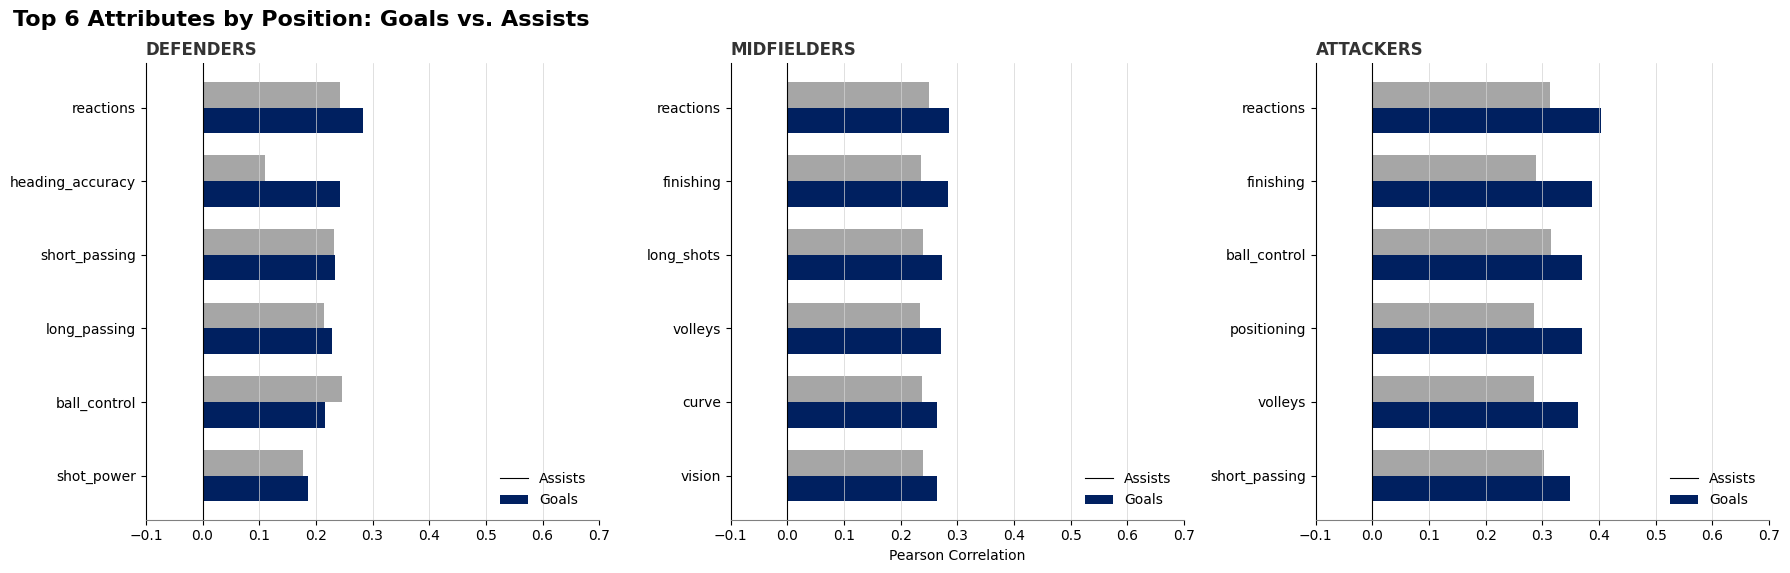

In [ ]:

plt.rcParams['font.family'] = 'sans-serif'
colors_ibcs = ['#002060', '#A6A6A6']

ignore_cols = ['goals_count', 'assists_count', 'scorer_points', 'player_api_id',
               'season', 'overall_rating', 'marking', 'standing_tackle',
               'sliding_tackle', 'interceptions']


fig = plt.figure(figsize=(18, 6))
fig.text(0.01, 0.95, 'Top 6 Attributes by Position: Goals vs. Assists', fontsize=16, fontweight='bold', ha='left')


#1. defenders
ax1 = plt.subplot(1, 3, 1)
df_def = fact_player_stats[fact_player_stats['position_class'] == 'Defender']
corr_def = df_def.corr(numeric_only=True)
plot_def = corr_def[['goals_count', 'assists_count']].drop(index=ignore_cols, errors='ignore')
plot_def['sum'] = plot_def['goals_count'] + plot_def['assists_count']
plot_def = plot_def.sort_values('sum', ascending=False).head(6)
plot_def = plot_def.drop(columns=['sum']).sort_values('goals_count')
plot_def.plot(kind='barh', ax=ax1, color=colors_ibcs, width=0.7)

ax1.set_title('DEFENDERS', loc='left', fontsize=12, fontweight='bold', color='#333333')
ax1.set_xlabel('')
ax1.set_ylabel('')
ax1.set_xlim(-0.1, 0.7)
ax1.axvline(0, color='black', linewidth=0.8)

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['bottom'].set_color('#808080')
ax1.spines['left'].set_visible(True)
ax1.grid(axis='x', color='lightgrey', linestyle='-', linewidth=0.5)

#legend
ax1.legend(['Assists', 'Goals'], frameon=False, loc='lower right')



# 2. middelfielders
ax2 = plt.subplot(1, 3, 2)

df_mid = fact_player_stats[fact_player_stats['position_class'] == 'Midfielder']
corr_mid = df_mid.corr(numeric_only=True)


plot_mid = corr_mid[['goals_count', 'assists_count']].drop(index=ignore_cols, errors='ignore')


plot_mid['sum'] = plot_mid['goals_count'] + plot_mid['assists_count']
plot_mid = plot_mid.sort_values('sum', ascending=False).head(6)
plot_mid = plot_mid.drop(columns=['sum']).sort_values('goals_count')

plot_mid.plot(kind='barh', ax=ax2, color=colors_ibcs, width=0.7)

ax2.set_title('MIDFIELDERS', loc='left', fontsize=12, fontweight='bold', color='#333333')
ax2.set_xlabel('Pearson Correlation')
ax2.set_ylabel('')
ax2.set_xlim(-0.1, 0.7)
ax2.axvline(0, color='black', linewidth=0.8)

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['bottom'].set_color('#808080')
ax2.spines['left'].set_visible(True)

ax2.grid(axis='x', color='lightgrey', linestyle='-', linewidth=0.5)

#legend
ax2.legend(['Assists', 'Goals'], frameon=False, loc='lower right')


# 3. attackers
ax3 = plt.subplot(1, 3, 3)


df_att = fact_player_stats[fact_player_stats['position_class'] == 'Attacker']
corr_att = df_att.corr(numeric_only=True)
plot_att = corr_att[['goals_count', 'assists_count']].drop(index=ignore_cols, errors='ignore')

plot_att['sum'] = plot_att['goals_count'] + plot_att['assists_count']
plot_att = plot_att.sort_values('sum', ascending=False).head(6)
plot_att = plot_att.drop(columns=['sum']).sort_values('goals_count')


plot_att.plot(kind='barh', ax=ax3, color=colors_ibcs, width=0.7)

ax3.set_title('ATTACKERS', loc='left', fontsize=12, fontweight='bold', color='#333333')
ax3.set_xlabel('')
ax3.set_ylabel('')
ax3.set_xlim(-0.1, 0.7)
ax3.axvline(0, color='black', linewidth=0.8)

ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.spines['bottom'].set_color('#808080')
ax3.spines['left'].set_visible(True)

ax3.grid(axis='x', color='lightgrey', linestyle='-', linewidth=0.5)
#legend
ax3.legend(['Assists', 'Goals'], frameon=False, loc='lower right')


plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

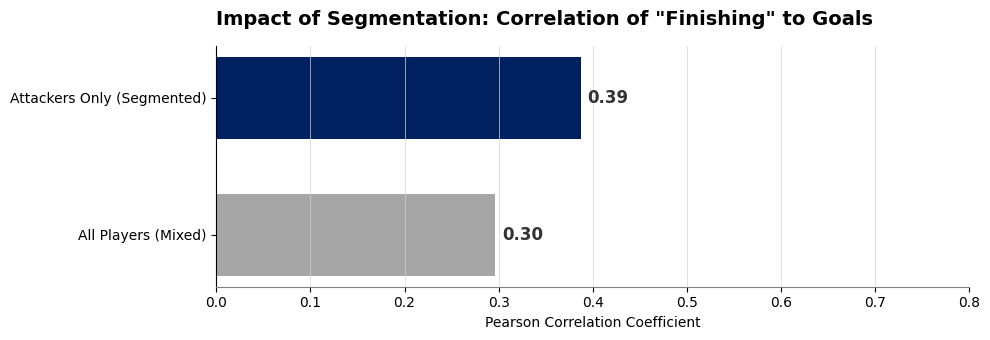

In [ ]:
# --- SETUP: IBCS Style ---
plt.rcParams['font.family'] = 'sans-serif'

# 1. BERECHNUNG (Beweis für Folie 3)
# A) Der "falsche" Weg: Korrelation über ALLE Spieler
corr_all = fact_player_stats['finishing'].corr(fact_player_stats['goals_count'])

# B) Der "richtige" Weg: Korrelation NUR für Angreifer
df_att = fact_player_stats[fact_player_stats['position_class'] == 'Attacker']
corr_att = df_att['finishing'].corr(df_att['goals_count'])

# Daten vorbereiten
values = [corr_all, corr_att]
labels = ['All Players (Mixed)', 'Attackers Only (Segmented)']

# FARBEN VON EBEN (Exakt dein Schema):
# Grau (#A6A6A6) für den "schlechten/alten" Weg
# Dunkelblau (#002060) für den "guten/neuen" Weg (Highlight)
colors_comparison = ['#A6A6A6', '#002060']

# --- PLOT ---
fig, ax = plt.subplots(figsize=(10, 3.5))

# Balken zeichnen
bars = ax.barh(labels, values, color=colors_comparison, height=0.6)

# WERTE ANZEIGEN (Datenbeschriftung ist Pflicht bei IBCS)
ax.bar_label(bars, fmt='%.2f', padding=5, fontsize=12, fontweight='bold', color='#333333')

# STYLING (SIMPLIFY & UNIFY)
ax.set_title('Impact of Segmentation: Correlation of "Finishing" to Goals', loc='left', fontsize=14, fontweight='bold', pad=15)
ax.set_xlim(0, 0.8) # Platz für Labels lassen
ax.set_xlabel('Pearson Correlation Coefficient')

# Rahmen entfernen (Clutter weg)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(True) # Links behalten für die Labels
ax.spines['bottom'].set_color('#808080')

# Gitter nur vertikal und dezent
ax.grid(axis='x', color='lightgrey', linestyle='-', linewidth=0.5)
ax.grid(axis='y', visible=False)

plt.tight_layout()
plt.show()

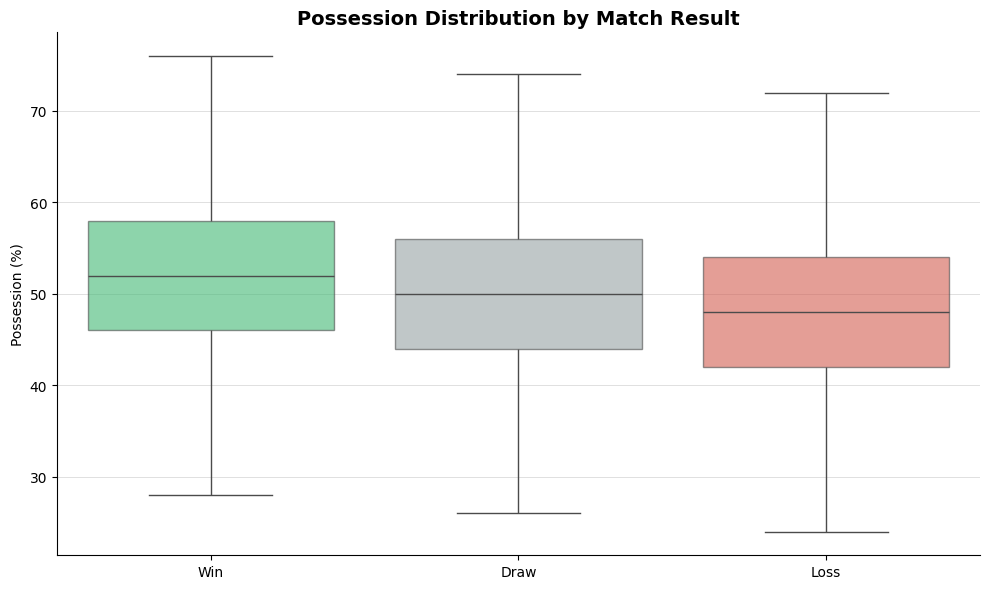

/tmp/ipython-input-389722092.py:85: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(x='possession_group', y='goal_diff', data=grouped_data,
/tmp/ipython-input-389722092.py:95: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45)


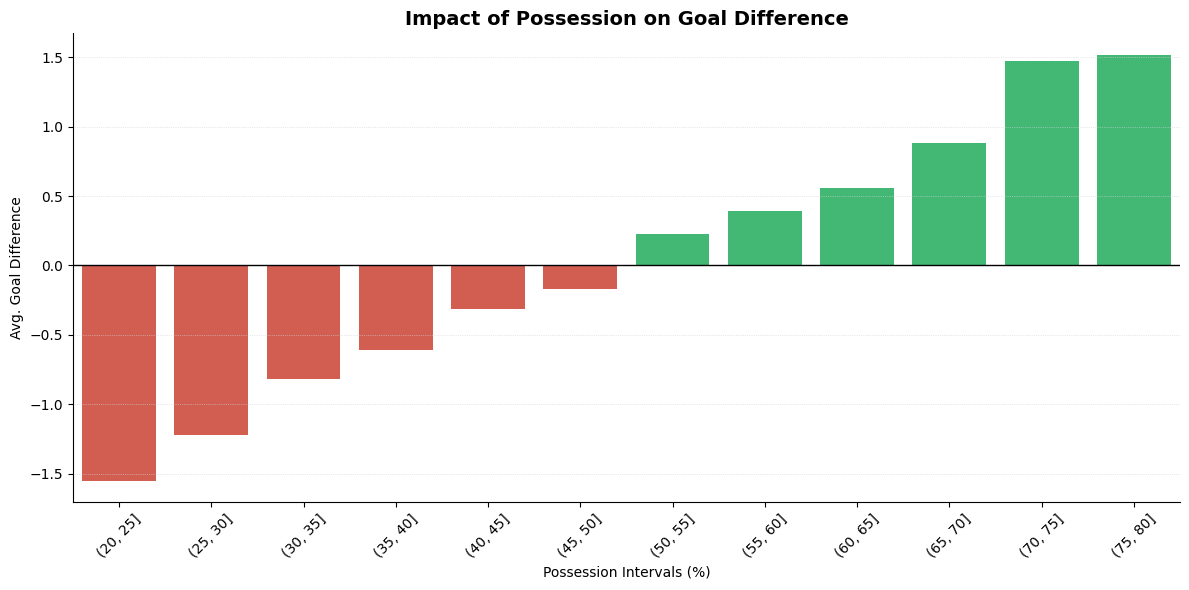

In [ ]:
#answer to question 2

# plt.figure(figsize=(10, 6))
# sns.boxplot(x='result', y='home_possession', data=clean_matches,
#             order=['HomeWin', 'Draw', 'AwayWin'], showmeans=True)
# plt.title('Possession based on Matchresults')
# plt.ylabel('Home-Possession (%)')
# plt.xlabel('Match-Results')
# plt.ylim(20, 80)
# plt.grid(axis='y', linestyle='--', alpha=0.7)
# plt.show()

# plt.figure(figsize=(10, 6))


# bins = list(range(20, 85, 5)) # [20, 25, 30, ... 80]
# clean_matches['possession_group'] = pd.cut(clean_matches['home_possession'], bins)

# grouped_data = clean_matches.groupby('possession_group')['goal_diff'].mean().reset_index()


# colors = ['#2ecc71' if x > 0 else '#e74c3c' for x in grouped_data['goal_diff']]

# plt.figure(figsize=(12, 6))
# sns.barplot(x='possession_group', y='goal_diff', data=grouped_data, palette=colors, edgecolor='black', alpha=0.8)
# plt.axhline(0, color='black', linewidth=1.5, linestyle='--'), plt.title('Influence of Possession on Match Success (Aggregated)', fontsize=14)
# plt.xlabel('Possession Brackets (%)', fontsize=12)
# plt.ylabel('Average Goal Difference', fontsize=12)
# plt.xticks(rotation=45)
# plt.grid(axis='y', linestyle=':', alpha=0.6)

# plt.tight_layout()
# plt.show()

# --- VORBEREITUNG ---
# Wir nehmen die Tabelle direkt, filtern nur Zeilen ohne Ballbesitz-Daten raus
#df_analysis = fact_match_stats.dropna(subset=['possession']).copy()

# --- VORBEREITUNG (Bleibt gleich) ---
df_analysis = fact_match_stats.copy()

# Datentyp erzwingen und bereinigen
df_analysis['possession'] = pd.to_numeric(df_analysis['possession'], errors='coerce')
df_analysis = df_analysis.dropna(subset=['possession'])

# --- STYLING SETUP ---
import seaborn as sns
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'sans-serif'
colors_ibcs_result = {'Win': '#2ecc71', 'Draw': '#95a5a6', 'Loss': '#e74c3c'}


plt.figure(figsize=(10, 6))

ax1 = sns.boxplot(x='result', y='possession', data=df_analysis,
            order=['Win', 'Draw', 'Loss'],
            hue='result', legend=False,
            boxprops=dict(alpha=.6), showfliers=False,
            palette=colors_ibcs_result)

ax1.set_title('Possession Distribution by Match Result', loc='center', fontsize=14, fontweight='bold')
ax1.set_xlabel('')
ax1.set_ylabel('Possession (%)')

# Styling
ax1.grid(axis='y', color='lightgrey', linestyle='-', linewidth=0.5)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 6))

# Daten vorbereiten
bins = list(range(20, 85, 5))
df_analysis['possession_group'] = pd.cut(df_analysis['possession'], bins)
grouped_data = df_analysis.groupby('possession_group', observed=False)['goal_diff'].mean().reset_index()

# Farbenlogik
colors_diff = ['#e74c3c' if x < 0 else '#2ecc71' for x in grouped_data['goal_diff']]

ax2 = sns.barplot(x='possession_group', y='goal_diff', data=grouped_data,
                  palette=colors_diff, hue=None)

ax2.set_title('Impact of Possession on Goal Difference', loc='center', fontsize=14, fontweight='bold')
ax2.axhline(0, color='black', linewidth=1)
ax2.set_xlabel('Possession Intervals (%)')
ax2.set_ylabel('Avg. Goal Difference')

# Styling
ax2.grid(axis='y', color='lightgrey', linestyle=':', linewidth=0.5)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.show() # <--- Zeigt das zweite Bild separat

In [ ]:
#answer to question 3
import matplotlib.ticker as ticker

plt.style.use('seaborn-v0_8-whitegrid')

trend_data = pd.merge(fact_match_stats, dim_time_2, on='time_key', how='inner')
trend_data = trend_data.rename(columns={'season_y': 'season'})
season_stats = trend_data.groupby('season')['total_goals'].sum().reset_index()
season_stats['change_rate'] = season_stats['total_goals'].pct_change() * 100

raw_query = """
SELECT season, home_team_goal, away_team_goal
FROM Match
"""
df_raw = pd.read_sql_query(raw_query, conn)
df_raw['match_total_goal'] = df_raw['home_team_goal'] + df_raw['away_team_goal']
df = df_raw.groupby('season')['match_total_goal'].mean().reset_index()
df.rename(columns={'match_total_goal': 'avg_team_goal'}, inplace=True)

fig, (ax1,ax2) = plt.subplots(2,1,figsize=(15,10))
fig.suptitle('Average Goals in Each Season and Change Over Time')

ax1.plot(df['season'],df['avg_team_goal'])
ax1.set_xlabel('Seasons')
ax1.set_ylabel('Goal')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(axis='y', linestyle='--', alpha=0.7)


####Change Over Time Graph#####

df['change rate']=df['avg_team_goal'].pct_change()*100

bar_colors = ['red' if x < 0 else 'green' for x in df['change rate']]
ax2.barh(df['season'],df['change rate'],color=bar_colors)
ax2.invert_yaxis()
ax2.set_xlabel('Goal Difference With Last Year')
ax2.set_ylabel('Seasons')
ax2.xaxis.set_major_formatter(ticker.PercentFormatter(decimals=None))
ax2.tick_params(labelrotation=45)


fig.tight_layout()
plt.show()

SyntaxError: invalid syntax (ipython-input-3606236719.py, line 17)

In [ ]:
# --- For Top 5 Leagues  ---

fact_query = """
SELECT league_id, season, home_team_goal, away_team_goal
FROM Match
"""

df_fact = pd.read_sql_query(fact_query, conn)

df_fact['total_team_goal'] = df_fact['home_team_goal'] + df_fact['away_team_goal']

dim_league_query = "SELECT id as league_id, name FROM League"
df_dim_league = pd.read_sql_query(dim_league_query, conn)

df_merged = pd.merge(df_fact, df_dim_league, on='league_id', how='inner')

top_5_leagues = [
    'England Premier League',
    'Spain LIGA BBVA',
    'Italy Serie A',
    'Germany 1. Bundesliga',
    'France Ligue 1'
]

df2_top5 = df_merged[df_merged['name'].isin(top_5_leagues)]

df2_top5 = df2_top5.groupby(['season', 'name'])['total_team_goal'].mean().reset_index()


plt.figure(figsize=(15,10))
sns.lineplot(data=df2_top5, x='season', y='total_team_goal', hue='name', marker='o')
plt.title('Average Goals in Each Season for Top 5 Leagues')
plt.xlabel('Seasons')
plt.ylabel('Average Goals')

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
tables = pd.read_sql("""SELECT name
                        FROM sqlite_master
                        WHERE type='table';""", conn)
print(tables)